## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Aitor\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [3]:
import os

path =r"C:\Users\Aitor\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3"
os.listdir(path)

['amz_uk_price_prediction_dataset.csv']

In [4]:
df=pd.read_csv(r"C:\Users\Aitor\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3\\amz_uk_price_prediction_dataset.csv")

---

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

In [5]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


* First of all, we check the information of the dataset to understand what categories appear and what type of data they have on it

In [7]:
freq_table = df['category'].value_counts().reset_index()
freq_table.columns = ['category', 'frecuency']
freq_table


,category,frecuency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Alexa Built-In Devices,107
292,Motorbike Chassis,107
293,Plugs,107
294,Smart Home Security & Lighting,104


In [8]:
top5_cat=freq_table.head()
top5_cat

,category,frecuency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


In [9]:
top5_cat=freq_table.head()
cat_list=top5_cat['category'].tolist()
print(f"The top 5 most listed product categories are \n {cat_list}")

The top 5 most listed product categories are 
 ['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories', 'Bath & Body', 'Birthday Gifts']


* As a result of this analysis, we can determine that the category 'Sports & Outdoors' is much bigger than the rest. this may be because the category is too big or to little determined
* The further analysis will be made with and without that category

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

C:\Users\Aitor\AppData\Local\Temp\ipykernel_34900\3649108496.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="category", y="frecuency", data=freq_table, palette="viridis", legend=False)


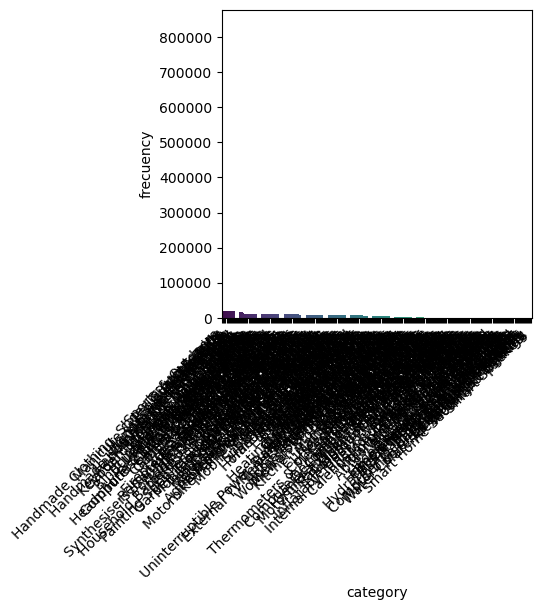

In [10]:
plt.figure(figsize=(4,4))
sns.barplot(x="category", y="frecuency", data=freq_table, palette="viridis", legend=False)
plt.xticks(rotation=45, ha='right')
plt.show()

C:\Users\Aitor\AppData\Local\Temp\ipykernel_34900\715394256.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="category", y="frecuency", data=freq_no_top, palette="viridis", legend=False)


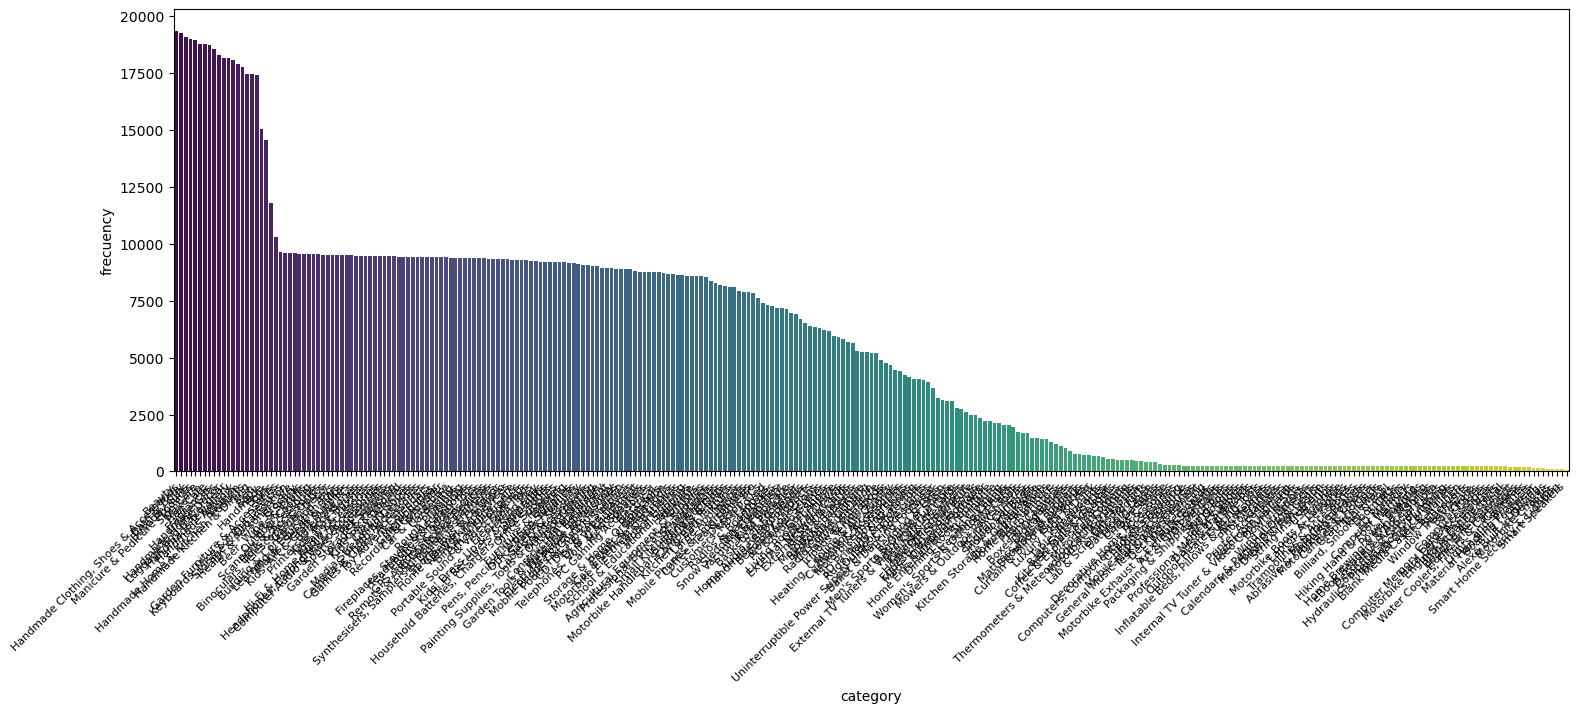

In [11]:
# We remove the most frecuent category
freq_no_top = freq_table.iloc[1:]
# We repeat the bar chart without it.
top5_no_first = freq_no_top.head(5)

plt.figure(figsize=(18,6))
sns.barplot(x="category", y="frecuency", data=freq_no_top, palette="viridis", legend=False)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.show()

* The barplot now shows the distribution better without the "Sports & Outdoors" category
* The are a few categories highly represented and also a lot with little frecuency,  making the curve of the graph very steep

For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

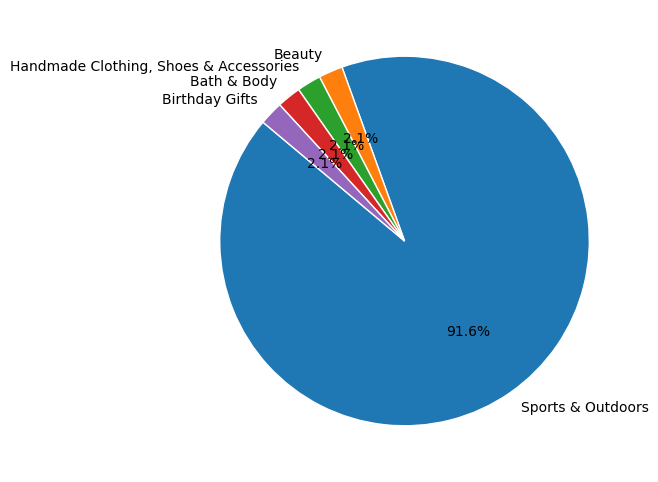

In [12]:
plt.figure(figsize=(6,6))
plt.pie(
    top5_cat['frecuency'],
    labels=top5_cat['category'],
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops={'edgecolor': 'white'}
)
plt.show()


* As indicated before, the "Sports & Outdoors" category is the most dominant, making the rest almost irrelevant

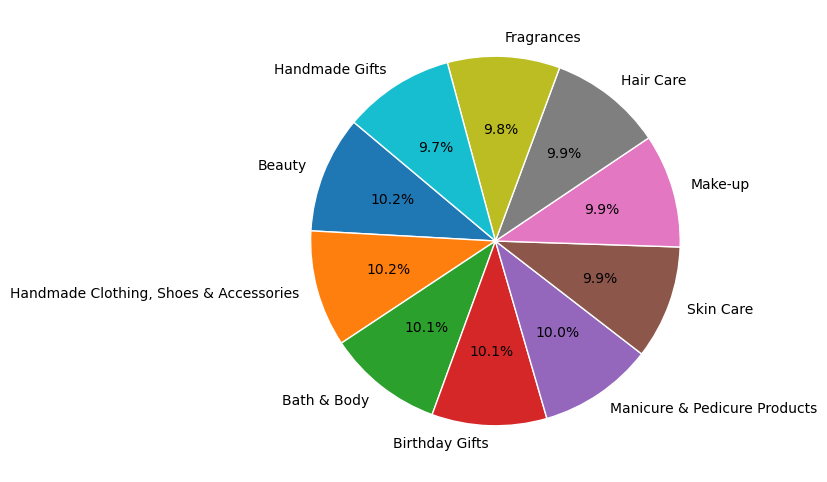

In [13]:
top10_no_first = freq_no_top.head(10)
plt.figure(figsize=(6,6))
plt.pie(
    top10_no_first['frecuency'],
    labels=top10_no_first['category'],
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops={'edgecolor': 'white'}
)
plt.show()

* If we remove again the outlier category, we can appreciate that the top 10 categories have similar results


---

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [14]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [15]:
mean_price=df['price'].mean().round(2)
median_price=df['price'].median()
mode_price=df['price'].mode()[0]

In [16]:
print(f"The mean of the price of products is {mean_price}, the median of the price of products is {median_price} and the mode of the price of products is {mode_price}")

The mean of the price of products is 89.24, the median of the price of products is 19.09 and the mode of the price of products is 9.99


* Having the mean bigger than the median indicates a right-skewed distribution. 
The majority of products are relatively low-priced, while a small number of high-priced items significantly increase the average
As a result, the mode and median represent the typical product price better than the mean 

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [17]:
df['price'].describe().round(2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

* With this we can have a quick look to the data asked, but we can also show it better

In [18]:
var_price=df['price'].var()
std_price=df['price'].std()
range_price=df['price'].max()-df['price'].min()
iqr_price=df['price'].quantile(0.75)-df['price'].quantile(0.25)

print(f"Variance: {var_price:.2f} \n"
f"Standard deviation: {std_price:.2f} \n"
f"Range: {range_price} \n"
f"Interquartile range {iqr_price}")

Variance: 119445.49 
Standard deviation: 345.61 
Range: 100000.0 
Interquartile range 36.0


* The product prices are highly varied, indicating a significant spread. 
The standard deviation is large relative to the median price, suggesting that while most products are low-priced, a few high-priced items pull the average up. 
The range is extremely wide, confirming the presence of extreme values (outliers). 
However, the interquartile range is much smaller than the full range, showing that the middle 50% of prices are more tightly clustered. 
These metrics together confirm the right-skewed distribution indicated before, and also a wide spread in prices due to a few very expensive products.

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

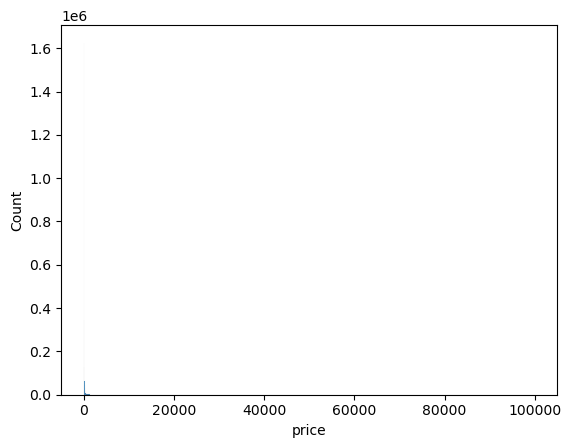

In [19]:
sns.histplot(df['price'], bins="auto", kde=False)
plt.show()

* Due to the fact that there are some products with a hig cost (the max was 100000) the histogram doesn't show the data of most of the products

* We're going to limit the product prices shown to 100 (which is still bigger than the quantile 3 (75%)) to have a better graphic

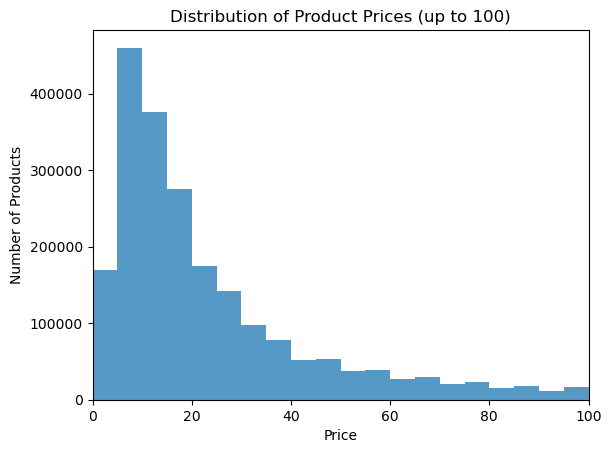

In [20]:
sns.histplot(df['price'], bins=20000, kde=False)
plt.xlim(0, 100)
plt.title("Distribution of Product Prices (up to 100)")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.show()

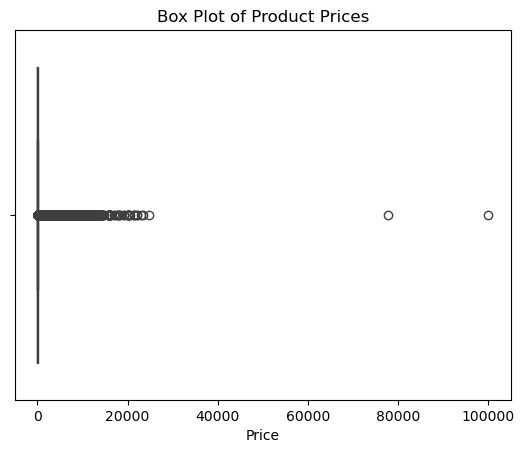

In [21]:
sns.boxplot(x=df['price'])
plt.title("Box Plot of Product Prices")
plt.xlabel("Price")
plt.show()


* With this box plot we can see that there are two main outliers in product pricing


---

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [22]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


* The data provided had rated all the products with stars from 0 to 5
* It also indicates that if 0 in 'stars', no ratings were found.
* However, we're going to make the calculations without taking into account the products that have **0 reviews** (this way we can consider 0 stars as a valid rating if there is at least 1 review)

In [23]:
df_no_zero_reviews = df[df['reviews'] != 0]
df_no_zero_reviews['stars'].describe().round(2)

count    1218010.00
mean           4.32
std            0.56
min            1.00
25%            4.10
50%            4.40
75%            4.60
max            5.00
Name: stars, dtype: float64

In [24]:
mean_stars=df_no_zero_reviews['stars'].mean().round(2)
median_stars=df_no_zero_reviews['stars'].median()
mode_stars=df_no_zero_reviews['stars'].mode()[0]

In [25]:
print(f"The mean of the rating of products is {mean_stars}, the median of the rating of products is {median_stars} and the mode of the rating of products is {mode_stars}")

The mean of the rating of products is 4.32, the median of the rating of products is 4.4 and the mode of the rating of products is 4.5


* Customers generally rate products positively. Most ratings are clustered between 4 and 5, with the most common rating being 4.5. This indicates a clear trend towards high satisfaction among users

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [26]:
var_stars=df_no_zero_reviews['stars'].var()
std_stars=df_no_zero_reviews['stars'].std()
range_stars=df_no_zero_reviews['stars'].max()-df_no_zero_reviews['stars'].min()
iqr_stars=df_no_zero_reviews['stars'].quantile(0.75)-df_no_zero_reviews['stars'].quantile(0.25)

print(f"Variance: {var_stars:.2f} \n"
f"Standard deviation: {std_stars:.2f} \n"
f"Range: {range_stars} \n"
f"Interquartile range {iqr_stars}")

Variance: 0.31 
Standard deviation: 0.56 
Range: 4.0 
Interquartile range 0.5


* Customer ratings are generally consistent. Most ratings are clustered around the mean, with a narrow interquartile range of 0.5, indicating that users tend to give similar feedback. 
* Although the full range is 4 points, the data shows low variability in ratings.

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [27]:
skewness = df_no_zero_reviews['stars'].skew()
kurtosis = df_no_zero_reviews['stars'].kurtosis()

print(f"Skewness of ratings: {skewness:.2f}")
print(f"Kurtosis of ratings: {kurtosis:.2f}")

Skewness of ratings: -2.38
Kurtosis of ratings: 9.78


* Customer ratings are strongly skewed toward high values, with most products receiving ratings close to 4–5. 
* Users tend to rate products very positively, and negative feedback is rare.

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

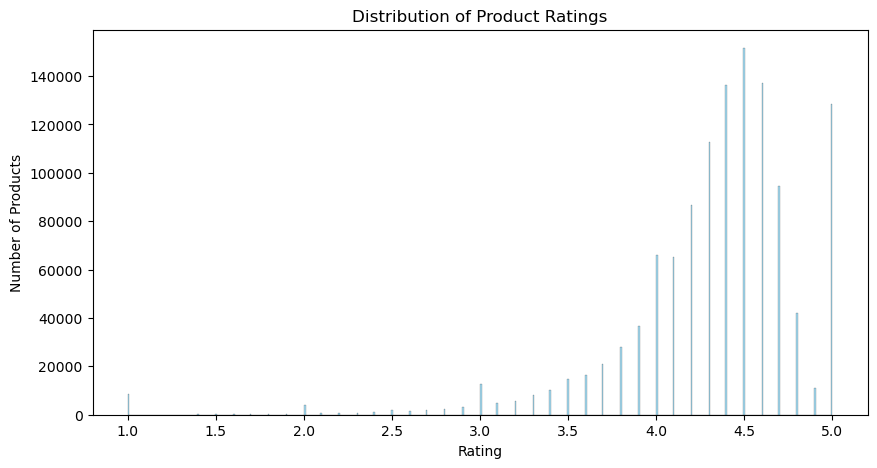

In [28]:
plt.figure(figsize=(10,5))

sns.histplot(df_no_zero_reviews['stars'], bins='auto', kde=False, color='skyblue')

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()


* The rating that is most common is 4.5, which is the one indicated by the mode

* Having most of the ratings between 3 and 5 stars, we can focus on that range

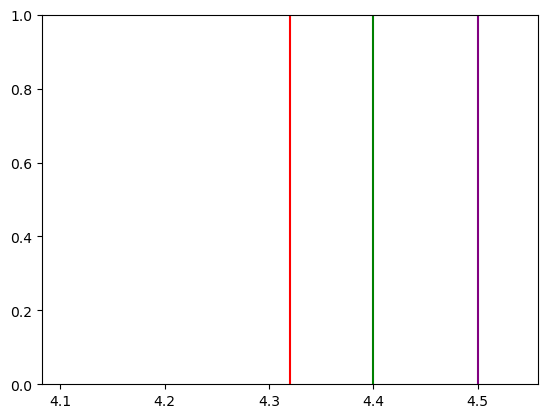

In [29]:
plt.axvline(mean_stars, color='red', label=f"Mean: {mean_stars:.2f}")
plt.axvline(median_stars, color='green', label=f"Median: {median_stars:.2f}")
plt.axvline(mode_stars, color='purple', label=f"Mode: {mode_stars:.2f}")

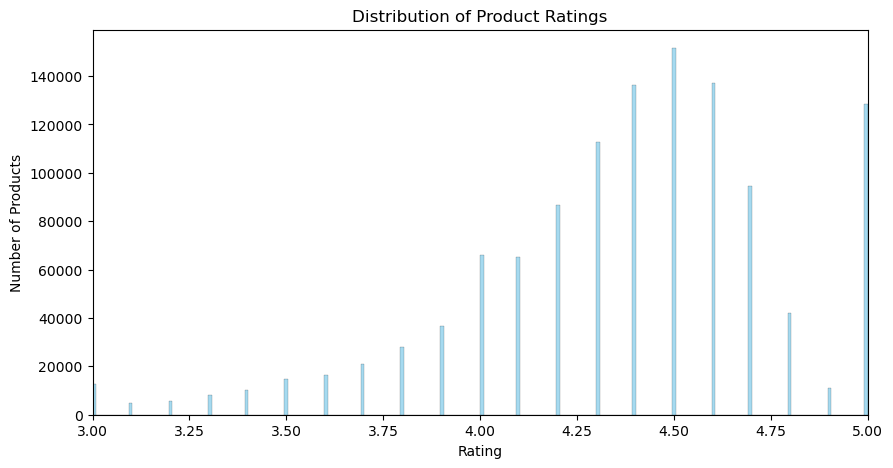

In [30]:
plt.figure(figsize=(10,5))

sns.histplot(df_no_zero_reviews['stars'], bins='auto', kde=False, color='skyblue')

plt.xlim(3, 5)
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()


* With this histogram (where there are no outliners with low ratings) we can confirm that most of the ratings are between 4 and 5. And therefore, the satisfaction of the customers is very high.